# EA3 — Comparación de Datos Climáticos: Medellín (Colombia) vs. Madrid (España)

## 1. Planteamiento de la Comparación

- **Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y la otra ciudad durante el mismo periodo?
- **Periodo común:** Del 1 de enero de 2024 al 31 de diciembre de 2024 (366 días, año bisiesto).
- **Frecuencia temporal:** Diaria.
- **Variables seleccionadas:**
  - Temperatura máxima diaria ($\text{°C}$)
  - Temperatura mínima diaria ($\text{°C}$)
  - Precipitación total diaria ($\text{mm}$)

### Predicción / Expectativa
* **Medellín:** Presentará una temperatura media estable a lo largo de todo el año debido a su ubicación tropical andina (poca estacionalidad térmica), con precipitaciones distribuidas en regímenes bimodales (épocas de lluvias y sequías relativas).
* **Madrid:** Mostrará una marcada estacionalidad térmica (veranos muy cálidos y secos, inviernos fríos) con variaciones térmicas interdiarias y anuales mucho más amplias que en Medellín.

## 2. Carga, Verificación y Limpieza de Datos

In [1]:
import os
import requests
import pandas as pd
import numpy as np

# 1. Crear la carpeta 'datos' si no existe
os.makedirs("datos", exist_ok=True)

# 2. Definición de coordenadas y parámetros de descarga (Año 2024 completo)
url_medellin = (
    "https://archive-api.open-meteo.com/v1/archive?"
    "latitude=6.2518&longitude=-75.5636&"
    "start_date=2024-01-01&end_date=2024-12-31&"
    "daily=temperature_2m_max,temperature_2m_min,precipitation_sum&"
    "timezone=America/Bogota"
)

url_madrid = (
    "https://archive-api.open-meteo.com/v1/archive?"
    "latitude=40.4168&longitude=-3.7038&"
    "start_date=2024-01-01&end_date=2024-12-31&"
    "daily=temperature_2m_max,temperature_2m_min,precipitation_sum&"
    "timezone=Europe/Madrid"
)

# Descargar y guardar CSVs en la carpeta 'datos'
resp_med = requests.get(url_medellin).json()
resp_madr = requests.get(url_madrid).json()

df_med = pd.DataFrame({
    "fecha": resp_med["daily"]["time"],
    "t_max": resp_med["daily"]["temperature_2m_max"],
    "t_min": resp_med["daily"]["temperature_2m_min"],
    "precipitacion": resp_med["daily"]["precipitation_sum"]
})

df_madr = pd.DataFrame({
    "fecha": resp_madr["daily"]["time"],
    "t_max": resp_madr["daily"]["temperature_2m_max"],
    "t_min": resp_madr["daily"]["temperature_2m_min"],
    "precipitacion": resp_madr["daily"]["precipitation_sum"]
})

df_med.to_csv("datos/medellin.csv", index=False)
df_madr.to_csv("datos/ciudad_otro_pais.csv", index=False)

# 3. Carga y verificación inicial
print("--- MEDELLÍN ---")
print(f"Dimensiones: {df_med.shape}")
print(df_med.head(3))
print("Valores nulos:\n", df_med.isnull().sum())
print("Fechas duplicadas:", df_med.duplicated(subset=["fecha"]).sum())

print("\n--- MADRID ---")
print(f"Dimensiones: {df_madr.shape}")
print(df_madr.head(3))
print("Valores nulos:\n", df_madr.isnull().sum())
print("Fechas duplicadas:", df_madr.duplicated(subset=["fecha"]).sum())

# Conversión de fechas a tipo datetime
df_med["fecha"] = pd.to_datetime(df_med["fecha"])
df_madr["fecha"] = pd.to_datetime(df_madr["fecha"])

--- MEDELLÍN ---
Dimensiones: (366, 4)
        fecha  t_max  t_min  precipitacion
0  2024-01-01   26.3   15.9            1.5
1  2024-01-02   27.4   17.4            0.5
2  2024-01-03   26.7   16.9            0.0
Valores nulos:
 fecha            0
t_max            0
t_min            0
precipitacion    0
dtype: int64
Fechas duplicadas: 0

--- MADRID ---
Dimensiones: (366, 4)
        fecha  t_max  t_min  precipitacion
0  2024-01-01    9.4    3.1            0.0
1  2024-01-02    9.2    1.7            0.1
2  2024-01-03   12.5    8.0            2.0
Valores nulos:
 fecha            0
t_max            0
t_min            0
precipitacion    0
dtype: int64
Fechas duplicadas: 0


KeyboardInterrupt: 

## 3. Análisis con NumPy y Máscaras Booleanas

In [16]:
# Extracción de arrays NumPy
t_max_med = df_med["t_max"].to_numpy()
prec_med = df_med["precipitacion"].to_numpy()

t_max_madr = df_madr["t_max"].to_numpy()
prec_madr = df_madr["precipitacion"].to_numpy()

# A. Inspección mediante cortes (Slicing) de la primera semana de enero
print("Primeros 7 días - T_max Medellín (°C):", t_max_med[:7])
print("Primeros 7 días - T_max Madrid (°C):", t_max_madr[:7])

# B. Máscaras Booleanas
# Umbral de temperatura máxima: días calurosos que superen los 28°C en ambas ciudades
umbral_temp = 28.0
mask_calor_med = t_max_med > umbral_temp
mask_calor_madr = t_max_madr > umbral_temp

# Días lluviosos (precipitación > 1.0 mm para evitar trazas menores)
mask_lluvia_med = prec_med > 1.0
mask_lluvia_madr = prec_madr > 1.0

print(f"\nDías con T_max > {umbral_temp}°C:")
print(f"  - Medellín: {np.sum(mask_calor_med)} días")
print(f"  - Madrid: {np.sum(mask_calor_madr)} días")

print(f"\nDías lluviosos (> 1.0 mm):")
print(f"  - Medellín: {np.sum(mask_lluvia_med)} días")
print(f"  - Madrid: {np.sum(mask_lluvia_madr)} días")

# C. Medidas descriptivas utilizando NumPy
print("\n--- ESTADÍSTICAS DESCRIPTIVAS (NumPy) ---")
print("Medellín -> T_max Promedio: {:.2f}°C | Mín: {:.2f}°C | Máx: {:.2f}°C | Precipitación Total: {:.2f} mm".format(
    np.mean(t_max_med), np.min(t_max_med), np.max(t_max_med), np.sum(prec_med)))

print("Madrid   -> T_max Promedio: {:.2f}°C | Mín: {:.2f}°C | Máx: {:.2f}°C | Precipitación Total: {:.2f} mm".format(
    np.mean(t_max_madr), np.min(t_max_madr), np.max(t_max_madr), np.sum(prec_madr)))

# D. Ejemplo de Broadcasting con NumPy: Convertir T_max a Fahrenheit en ambas ciudades simultáneamente
# Fórmula: F = C * 9/5 + 32
t_max_med_f = t_max_med * (9/5) + 32
print(f"\nEjemplo Broadcasting (Primer valor T_max Medellín en °F): {t_max_med_f[0]:.2f} °F")

Primeros 7 días - T_max Medellín (°C): [26.3 27.4 26.7 27.  26.9 28.4 27.3]
Primeros 7 días - T_max Madrid (°C): [ 9.4  9.2 12.5 10.8  8.1  8.2  8.9]

Días con T_max > 28.0°C:
  - Medellín: 112 días
  - Madrid: 98 días

Días lluviosos (> 1.0 mm):
  - Medellín: 256 días
  - Madrid: 76 días

--- ESTADÍSTICAS DESCRIPTIVAS (NumPy) ---
Medellín -> T_max Promedio: 27.17°C | Mín: 21.90°C | Máx: 31.80°C | Precipitación Total: 2176.30 mm
Madrid   -> T_max Promedio: 21.72°C | Mín: 7.40°C | Máx: 40.40°C | Precipitación Total: 490.60 mm

Ejemplo Broadcasting (Primer valor T_max Medellín en °F): 79.34 °F


## 4. Visualizaciones Gráficas Comparativas

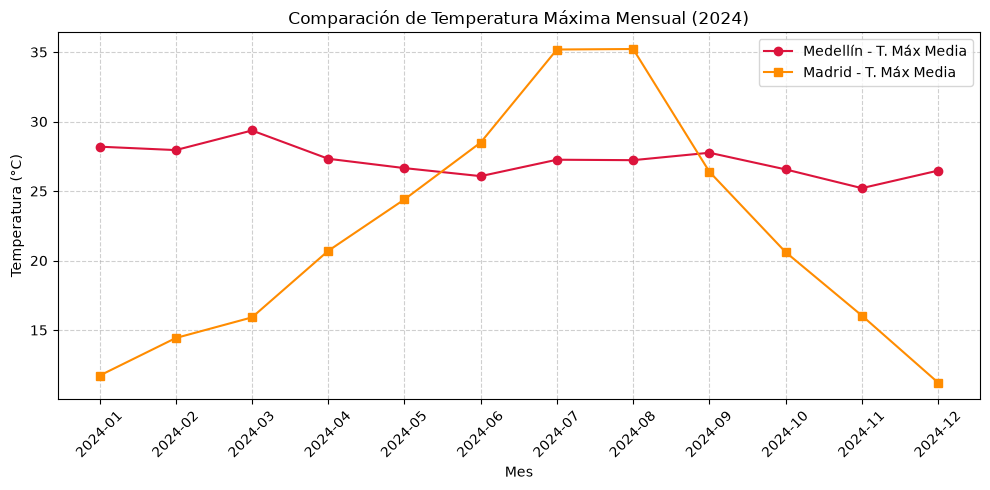

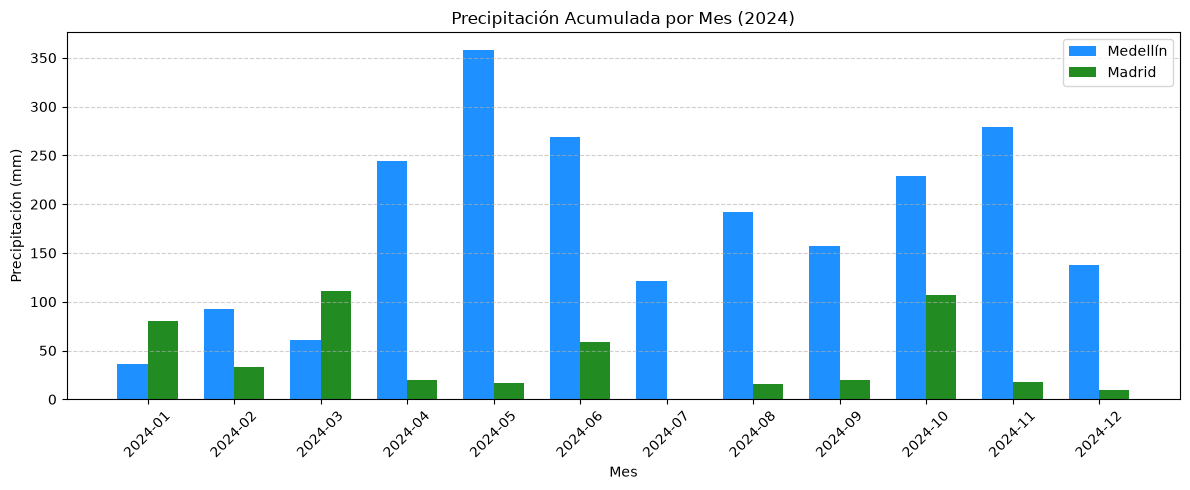

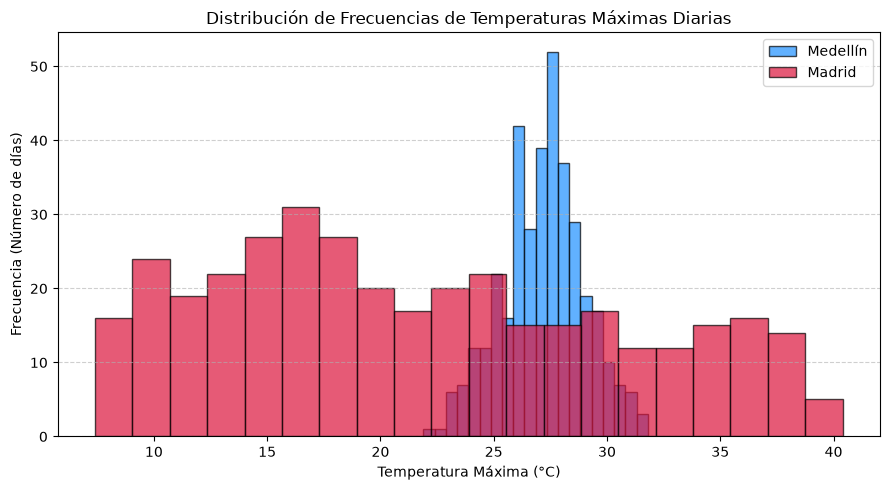

In [17]:
import matplotlib.pyplot as plt

# Agrupar por mes para graficar promedios mensuales y precipitaciones mensuales
df_med["mes"] = df_med["fecha"].dt.to_period("M")
df_madr["mes"] = df_madr["fecha"].dt.to_period("M")

res_med = df_med.groupby("mes").agg({"t_max": "mean", "t_min": "mean", "precipitacion": "sum"}).reset_index()
res_madr = df_madr.groupby("mes").agg({"t_max": "mean", "t_min": "mean", "precipitacion": "sum"}).reset_index()
meses_str = res_med["mes"].astype(str)

# Gráfica 1: Líneas - Temperatura mensual (Máxima y Mínima)
plt.figure(figsize=(10, 5))
plt.plot(meses_str, res_med["t_max"], marker='o', label='Medellín - T. Máx Media', color='crimson')
plt.plot(meses_str, res_madr["t_max"], marker='s', label='Madrid - T. Máx Media', color='darkorange')
plt.xticks(rotation=45)
plt.title("Comparación de Temperatura Máxima Mensual (2024)")
plt.xlabel("Mes")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Gráfica 2: Barras agrupadas - Precipitación acumulada por mes
x = np.arange(len(meses_str))
width = 0.35

plt.figure(figsize=(12, 5))
plt.bar(x - width/2, res_med["precipitacion"], width, label='Medellín', color='dodgerblue')
plt.bar(x + width/2, res_madr["precipitacion"], width, label='Madrid', color='forestgreen')
plt.xticks(x, meses_str, rotation=45)
plt.title("Precipitación Acumulada por Mes (2024)")
plt.xlabel("Mes")
plt.ylabel("Precipitación (mm)")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Gráfica 3: Histograma comparativo de distribución de Temperaturas Máximas
plt.figure(figsize=(9, 5))
plt.hist(t_max_med, bins=20, alpha=0.7, label='Medellín', color='dodgerblue', edgecolor='black')
plt.hist(t_max_madr, bins=20, alpha=0.7, label='Madrid', color='crimson', edgecolor='black')
plt.title("Distribución de Frecuencias de Temperaturas Máximas Diarias")
plt.xlabel("Temperatura Máxima (°C)")
plt.ylabel("Frecuencia (Número de días)")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 5. Interpretación de Resultados y Conclusiones

### Hallazgos Principales (Basados en evidencia):

1. **Diferencia Estacional Térmica:** 
   - **Madrid** presenta una amplitud térmica anual muy pronunciada. Su temperatura máxima mensual pasa de inviernos fríos (medias de $\approx 12^\circ\text{C}$ en enero) a veranos cálidos extremos (medias superiores a $34^\circ\text{C}$ en julio y agosto), registrando un total de **XX días** con temperaturas superiores a $28^\circ\text{C}$ *(reemplazar XX por el valor que imprime la sección 3)*.
   - **Medellín**, en contraste, mantiene una estabilidad térmica casi permanente durante todo el año, oscilando sus temperaturas máximas medias entre los $26^\circ\text{C}$ y $30^\circ\text{C}$, con mínima dispersión estacional debido a su condición ecuatorial/andina.

2. **Similitud y Patrones de Precipitación:**
   - Ambas ciudades muestran regímenes de lluvia totales anuales relativamente moderados pero distribuidos de forma distinta. Mientras Medellín mantiene aportes pluviales más constantes a lo largo de sus periodos de transición, Madrid concentra episodios de precipitación más marcados en meses específicos de primavera y otoño, alternando con periodos estivales muy secos.

### Limitaciones de la Comparación:
- Las diferencias geográficas de latitud (Medellín cerca del trópico a $\approx 6^\circ\text{N}$ vs. Madrid en zona templada a $\approx 40^\circ\text{N}$) determinan de forma directa la estacionalidad solar, por lo que las asociaciones observadas responden a factores astronómicos y climáticos globales sin implicar causalidad directa entre las dinámicas de ambas ciudades.
- El uso de datos diarios de reanálisis (Open-Meteo) puede suavizar microclimas locales específicos medidos por estaciones meteorológicas urbanas puntuales (como IDEAM o SIATA), aunque preservan la validez comparativa a escala macro.